<a href="https://colab.research.google.com/github/Basharbalaa/chicago-food-inspections/blob/main/Chicago_food_inspections.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import pandas as pd

df = pd.read_csv("/content/drive/MyDrive/chicago-inspections/food_inspections.zip")
df.shape

(318244, 17)

In [ ]:
df.head()

,Inspection ID,DBA Name,AKA Name,License #,Facility Type,Risk,Address,City,State,Zip,Inspection Date,Inspection Type,Results,Violations,Latitude,Longitude,Location
0,2646614,SEE THRU CHINESE KITCHEN,SEE THRU CHINESE KITCHEN,36468.0,Restaurant,Risk 1 (High),10939 S WESTERN AVE,CHICAGO,IL,60643.0,11/10/2026,Complaint Re-Inspection,Pass,37. FOOD PROPERLY LABELED; ORIGINAL CONTAINER ...,41.694221,-87.681086,"(41.69422064707933, -87.68108589547474)"
1,2646610,THE SIAM LOTUS THAI CUISINE LLC,THE SIAM LOTUS THAI CUISINE,3105008.0,Restaurant,Risk 1 (High),3445 W 51ST ST,CHICAGO,IL,60632.0,11/10/2026,License Re-Inspection,Pass,51. PLUMBING INSTALLED; PROPER BACKFLOW DEVICE...,41.800619,-87.710456,"(41.80061941881158, -87.71045584912062)"
2,2646574,"LA CIUDAD DE PIEDRADURA , INC.",LA CIUDAD DE PIEDRADURA,3100520.0,Restaurant,Risk 1 (High),4781 S ARCHER AVE,CHICAGO,IL,60632.0,11/10/2026,License,Fail,"1. PERSON IN CHARGE PRESENT, DEMONSTRATES KNOW...",41.806668,-87.716128,"(41.80666845625096, -87.71612754564387)"
3,2646594,FOOD EXPRESS,FOOD EXPRESS,3096350.0,Restaurant,Risk 1 (High),113 E 51ST ST,CHICAGO,IL,60615.0,11/10/2026,License Re-Inspection,Pass,NaN,41.801900,-87.622018,"(41.80190047384105, -87.62201755519536)"
4,2646562,WUNDERKIND LEARNING CENTER,WUNDERKIND LEARNING CENTER,3104928.0,Daycare Above and Under 2 Years,Risk 1 (High),6842-6844 W ARCHER AVE,CHICAGO,IL,60638.0,11/10/2026,License,Pass,NaN,41.792233,-87.793284,"(41.79223321698213, -87.7932838035596)"


In [ ]:
df.tail()

,Inspection ID,DBA Name,AKA Name,License #,Facility Type,Risk,Address,City,State,Zip,Inspection Date,Inspection Type,Results,Violations,Latitude,Longitude,Location
318239,67757,DUNKIN DONUTS/BASKIN-ROBBINS,DUNKIN DONUTS/BASKIN-ROBBINS,1380279.0,Restaurant,Risk 2 (Medium),100 W RANDOLPH ST,CHICAGO,IL,60601.0,01/04/2010,Tag Removal,Pass,NaN,41.884586,-87.631010,"(41.88458626715456, -87.63101044588599)"
318240,70269,mr.daniel's,mr.daniel's,1899292.0,Restaurant,Risk 1 (High),5645 W BELMONT AVE,CHICAGO,IL,60634.0,01/04/2010,License Re-Inspection,Pass,NaN,41.938443,-87.768318,"(41.93844282365204, -87.76831838068422)"
318241,67732,WOLCOTT'S,TROQUET,1992039.0,Restaurant,Risk 1 (High),1834 W MONTROSE AVE,CHICAGO,IL,60613.0,01/04/2010,License Re-Inspection,Pass,NaN,41.961606,-87.675967,"(41.961605669949854, -87.67596676683779)"
318242,52234,Cafe 608,Cafe 608,2013328.0,Restaurant,Risk 1 (High),608 W BARRY AVE,CHICAGO,IL,60657.0,01/04/2010,License Re-Inspection,Pass,NaN,41.938007,-87.644755,"(41.938006880423615, -87.6447545707008)"
318243,67733,WOLCOTT'S,TROQUET,1992040.0,Restaurant,Risk 1 (High),1834 W MONTROSE AVE,CHICAGO,IL,60613.0,01/04/2010,License Re-Inspection,Pass,NaN,41.961606,-87.675967,"(41.961605669949854, -87.67596676683779)"


In [4]:
df["Inspection Date"] = pd.to_datetime(df["Inspection Date"], format="%m/%d/%Y")
print(df["Inspection Date"].min())
print(df["Inspection Date"].max())

2010-01-04 00:00:00
2026-11-10 00:00:00


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 318244 entries, 0 to 318243
Data columns (total 17 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   Inspection ID    318244 non-null  int64  
 1   DBA Name         318244 non-null  object 
 2   AKA Name         315819 non-null  object 
 3   License #        318225 non-null  float64
 4   Facility Type    312886 non-null  object 
 5   Risk             318155 non-null  object 
 6   Address          318244 non-null  object 
 7   City             318060 non-null  object 
 8   State            318168 non-null  object 
 9   Zip              318202 non-null  float64
 10  Inspection Date  318244 non-null  object 
 11  Inspection Type  318243 non-null  object 
 12  Results          318244 non-null  object 
 13  Violations       228356 non-null  object 
 14  Latitude         317180 non-null  float64
 15  Longitude        317180 non-null  float64
 16  Location         317180 non-null  obje

In [ ]:
df.isnull().sum()

,0
Inspection ID,0
DBA Name,0
AKA Name,2425
License #,19
Facility Type,5358
Risk,89
Address,0
City,184
State,76
Zip,42


In [ ]:
df["Results"].value_counts()

,count
Results,
Pass,164795
Fail,61254
Pass w/ Conditions,47122
Out of Business,26012
No Entry,14306
Not Ready,4659
Business Not Located,96


In [5]:
df["Inspection Date"].dt.year.value_counts().sort_index()

,count
Inspection Date,
2010,18068
2011,18747
2012,18866
2013,20947
2014,21540
2015,20911
2016,22818
2017,21587
2018,17191


In [6]:
df["Year"] = df["Inspection Date"].dt.year
pd.crosstab(df["Year"], df["Results"], normalize="index").round(3)

Results,Business Not Located,Fail,No Entry,Not Ready,Out of Business,Pass,Pass w/ Conditions
Year,,,,,,,
2010,0.001,0.249,0.000,0.000,0.037,0.634,0.079
2011,0.001,0.232,0.000,0.000,0.061,0.625,0.081
2012,0.001,0.193,0.013,0.000,0.137,0.575,0.081
2013,0.000,0.160,0.034,0.000,0.151,0.571,0.084
2014,0.000,0.173,0.035,0.000,0.100,0.585,0.107
2015,0.000,0.172,0.042,0.012,0.090,0.580,0.103
2016,0.000,0.188,0.047,0.015,0.068,0.567,0.115
2017,0.000,0.191,0.054,0.020,0.070,0.567,0.099
2018,0.000,0.193,0.040,0.027,0.069,0.371,0.300


In [7]:
df["Inspection Date"].dt.to_period("M").value_counts().sort_index()

,count
Inspection Date,
2010-01,1279
2010-02,1400
2010-03,1480
2010-04,1438
2010-05,1542
...,...
2026-07,1245
2026-08,1285
2026-09,1144


In [ ]:
df["Facility Type"].value_counts().head(10)

,count
Facility Type,
Restaurant,215955
Grocery Store,38108
School,19875
Children's Services Facility,7894
Bakery,4575
Daycare Above and Under 2 Years,4198
Daycare (2 - 6 Years),3279
Long Term Care,2449
Catering,1968


In [ ]:
df["Inspection Type"].value_counts().head(10)

,count
Inspection Type,
Canvass,164066
License,42717
Canvass Re-Inspection,35470
Complaint,30255
License Re-Inspection,12898
Complaint Re-Inspection,12732
Short Form Complaint,9386
Non-Inspection,5809
Suspected Food Poisoning,1028


In [ ]:
df["Risk"].value_counts()

,count
Risk,
Risk 1 (High),237029
Risk 2 (Medium),56389
Risk 3 (Low),24648
All,89


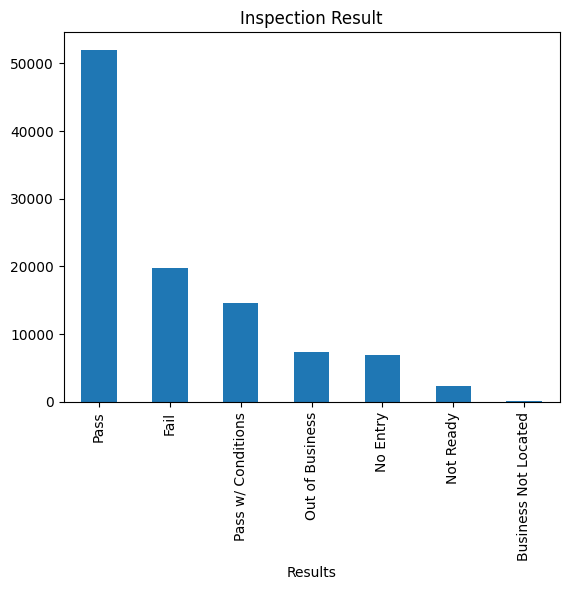

In [ ]:
import matplotlib.pyplot as plt
df["Results"].value_counts().plot(kind="bar")
plt.title("Inspection Result")
plt.show()

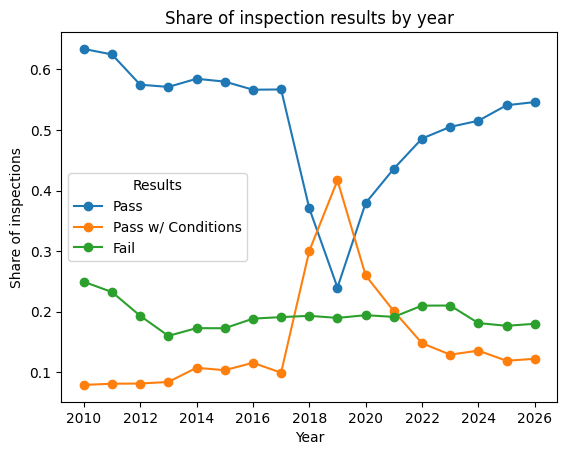

In [8]:
import matplotlib.pyplot as plt

shares = pd.crosstab(df["Year"], df["Results"], normalize="index")
shares[["Pass", "Pass w/ Conditions", "Fail"]].plot(kind="line", marker="o")
plt.title("Share of inspection results by year")
plt.ylabel("Share of inspections")
plt.show()

In [ ]:
df[df["Results"].isnull()]

,Inspection ID,DBA Name,AKA Name,License #,Facility Type,Risk,Address,City,State,Zip,Inspection Date,Inspection Type,Results,Violations,Latitude,Longitude,Location
102893,{,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN
102894,"""error"" : true",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN
102895,"""message"" : ""Internal error""",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN
102896,"""status"" : 500",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN
102897,},NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
df["Violations"].isnull().groupby(df["Results"]).mean()

,Violations
Results,
Business Not Located,1.000000
Fail,0.024212
No Entry,0.966336
Not Ready,0.991980
Out of Business,0.998352
Pass,0.291137
Pass w/ Conditions,0.026823


In [ ]:
df["Year"] = df["Inspection Date"].dt.year
pd.crosstab(df["Year"], df["Results"], normalize="index").round(3)

Results,Business Not Located,Fail,No Entry,Not Ready,Out of Business,Pass,Pass w/ Conditions
Year,,,,,,,
2010,0.001,0.249,0.000,0.000,0.037,0.634,0.079
2011,0.001,0.232,0.000,0.000,0.061,0.625,0.081
2012,0.001,0.193,0.013,0.000,0.137,0.575,0.081
2013,0.000,0.160,0.034,0.000,0.151,0.571,0.084
2014,0.000,0.173,0.035,0.000,0.100,0.585,0.107
2015,0.000,0.172,0.042,0.012,0.090,0.580,0.103
2016,0.000,0.188,0.047,0.015,0.068,0.567,0.115
2017,0.000,0.191,0.054,0.020,0.070,0.567,0.099
2018,0.000,0.193,0.040,0.027,0.069,0.371,0.300


In [ ]:
monthly = df["Inspection Date"].dt.to_period("M").value_counts().sort_index()
monthly.loc["2025-01":]

,count
Inspection Date,
2025-01,1600
2025-02,1506
2025-03,1802
2025-04,1876
2025-05,1666
2025-06,1475
2025-07,1678
2025-08,1498
2025-09,1529


In [ ]:
monthly[monthly < 1000]

,count
Inspection Date,
2021-02,974
2026-11,226


In [ ]:
(df["License #"] == 0).sum()

np.int64(840)

In [10]:
zero_lic = df[df["License #"] == 0]


In [ ]:
zero_lic["Facility Type"].value_counts().head()


,count
Facility Type,
Restaurant,210
Special Event,174
Shelter,64
School,49
CHURCH,35


In [ ]:
zero_lic["Inspection Type"].value_counts().head()

,count
Inspection Type,
Canvass,403
Complaint,141
Canvass Re-Inspection,76
Complaint Re-Inspection,69
Short Form Complaint,48


In [ ]:
monthly.loc["2019-10":"2020-12"]

,count
Inspection Date,
2019-10,1809
2019-11,1580
2019-12,1562
2020-01,1725
2020-02,1327
2020-03,1581
2020-04,1285
2020-05,1299
2020-06,1202


In [ ]:
len(monthly)

203

In [11]:
zero_lic["Facility Type"].value_counts().head()

,count
Facility Type,
Restaurant,210
Special Event,174
Shelter,64
School,49
CHURCH,35


# Week 1 Summary:

### Data Size:
318,244 rows and 17 columns, from 2010-01-04 to 2026-11-10.
### Results:
About 52% Pass, 19% Fail, 15% Pass w/ Conditions, and the rest are cases where no real inspection happened.
### Missing data:
Violations is missing in 28% of rows (mostly Passes and no-entry cases). Latitude and longitude are missing in about 0.3%.
### Surprise 1:
Around 2018, the split between Pass and Pass w/ Conditions changed a lot, but Fail stayed near 19%. On the line graph it shows both Pass and Pass w/ Conditions crosses each other.
### Surprise 2:
My first download was cut off by a server error, which I found by looking at the last rows. Also, 840 rows have a license number of 0, and the latest months of 2026 may be incomplete.